<a href="https://colab.research.google.com/github/shammun/gis-map-tutorials/blob/main/tutorials/gis_styles/03_block_diagram_colab.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Storm Ciarán crosses north-west Europe.** Makes the poster and the video of Storm Ciarán's 10-m wind on a 3-D block of north-west Europe, with a wind chart for Brest and London.

This is the executed notebook (outputs kept). The same recipe as a script: `03_block_diagram.py`; for Google Colab: `03_block_diagram_colab.ipynb` (the badge opens it).

[Gallery](https://shammun.github.io/gis-map-tutorials/) · [this recipe as a web page](https://shammun.github.io/gis-map-tutorials/tutorials/03_block_diagram.html) · [repository](https://github.com/shammun/gis-map-tutorials) · Map created by Shammunul Islam

# 3 · 3-D block diagram with a draped field and a linked chart

**The idea.** Cut a rectangular piece of the Earth out like a slice of cake, exaggerate its relief, look at it
from above and to one side, and drape a data field on its surface. Animate the field, and let a small chart of
the same field at one or two places carry the playhead. Relief gives the eye a sense of place that a flat map
does not; the chart gives the numbers that the oblique view cannot.

**This map.** Storm Ciarán's 10-m wind (ERA5, hourly) on the relief of north-west Europe (ETOPO 2022).

No 3-D library is used: the block is drawn with numpy only, and that is what this tutorial explains.

Steps: 1 data → 2 the camera → 3 "which ground does each pixel see" → 4 light and walls → 5 drape the
field → 6 the finished frame → 7 the animation.

<div style="background:#FFF3E0;border:3px solid #E65100;border-left:14px solid #E65100;border-radius:6px;padding:12px 16px;margin:8px 0;color:#1b1b1b">
<div style="color:#E65100;font-size:19px;font-weight:bold">CHANGE IF YOU LIKE — RUN</div>
<div style="font-size:16px;font-weight:bold;margin-top:4px">Settings</div>
</div>

Everything you may want to change is in this one cell. The checks at the bottom **stop** the notebook with a plain
message if a setting cannot work, before anything slow starts.

`MODE = "FAST"` (the default, one to three minutes; right for Google Colab) writes the poster at 1920 × 1080 px and a short
preview clip of the animation at 960 × 540 px. `MODE = "FULL"` writes the poster at 3840 × 2160 px and the whole
animation at 1920 × 1080 px (several minutes).

In [1]:
import os
import sys

MODE = "FULL" if "--full" in sys.argv else os.environ.get("GIS_MODE", "FAST")   # "FAST" (preview) or "FULL" (poster size, whole animation)
OUT_DIR = os.environ.get("GIS_OUT", "")          # output folder; "" = /content/out on Google Colab, ./out anywhere else
HOUR = 27                                        # the hour drawn: hours after 00 UTC 1 November 2023 (0 to 47); 27 = 03 UTC 2 November
AZIMUTH, TILT = 24.0, 35.0                       # the camera: direction it looks towards (degrees from north), height above the horizon

from gismaps import nb                           # helpers: data loader, show(), video(), STOP checks, PASS / FAIL

nb.stop_unless(MODE in ("FAST", "FULL"), f"MODE = {MODE!r} must be FAST or FULL")
nb.stop_unless(0 <= HOUR <= 47, f"HOUR = {HOUR} must be between 0 and 47")
nb.stop_unless(15 <= TILT <= 75, f"TILT = {TILT}: below 15 degrees the block is a sliver, above 75 it is a flat map")
POSTER_SCALE = 1.0 if MODE == "FAST" else 2.0    # the design size is 1920 x 1080; the poster is saved at this multiple
OUT = nb.out_dir(OUT_DIR)
print(f"settings OK | mode: {MODE} | output folder: {OUT} | poster {int(1920 * POSTER_SCALE)} x {int(1080 * POSTER_SCALE)} px")

settings OK | mode: FAST | output folder: out | poster 1920 x 1080 px


<div style="background:#E8F5E9;border:3px solid #2E7D32;border-left:14px solid #2E7D32;border-radius:6px;padding:12px 16px;margin:8px 0;color:#1b1b1b">
<div style="color:#2E7D32;font-size:19px;font-weight:bold">RUN</div>
<div style="font-size:16px;font-weight:bold;margin-top:4px">1 · The data</div>
</div>

Two small files: the hourly ERA5 10-m wind of Storm Ciarán (Copernicus Climate Change Service / ECMWF) and the
relief of north-west Europe at 2 arc-minutes (ETOPO 2022, NOAA NCEI, public domain).

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from gismaps.styles import common as C, block      # the map-style code of this repository

wind = nb.load("ciaran")                     # hourly ERA5 10-m wind components (cm/s) and pressure
terrain = nb.load("terrain_nweurope")        # ETOPO 2022 at 2 arc-minutes: z_m (row 0 = south), lat, lon
z, lat, lon = terrain["z_m"], terrain["lat"], terrain["lon"]
print("terrain", z.shape, "| highest point", z.max(), "m | wind hours", len(wind["time"]))

terrain (540, 660) | highest point 3923 m | wind hours 48


<div style="background:#E8F5E9;border:3px solid #2E7D32;border-left:14px solid #2E7D32;border-radius:6px;padding:12px 16px;margin:8px 0;color:#1b1b1b">
<div style="color:#2E7D32;font-size:19px;font-weight:bold">RUN</div>
<div style="font-size:16px;font-weight:bold;margin-top:4px">2 · The camera</div>
</div>

A parallel (orthographic) camera has two angles: the **azimuth** it looks towards (24° = towards north-
north-east, so the south edge is nearest to us) and its **tilt** above the horizon (35°). A point that lies
`v` km away from us along the ground and `h` metres high lands on the screen at

`screen_y = y0 − v · sin(tilt) / (km per pixel) − h · (exaggeration) · cos(tilt) / (km per pixel)`

Going further away moves a point up the screen; so does height. Relief is exaggerated 40 times here and the
figure says so: at true scale the Alps (4 km) on a 2000-km block would be two pixels high.

<div style="background:#E8F5E9;border:3px solid #2E7D32;border-left:14px solid #2E7D32;border-radius:6px;padding:12px 16px;margin:8px 0;color:#1b1b1b">
<div style="color:#2E7D32;font-size:19px;font-weight:bold">RUN</div>
<div style="font-size:16px;font-weight:bold;margin-top:4px">3 · Which ground does each pixel see?</div>
</div>

Turn the terrain so the camera looks straight "up the rows" (row 0 nearest). In one screen column, walk away
from the camera: each row's surface reaches some screen height. A pixel shows the **nearest** row whose surface
reaches at least that high. `Block` finds this for all pixels at once:

1. compute the screen height of every (row, column) cell;
2. write each row number into an image at that height, keeping the smallest row (`np.minimum.at`);
3. fill downwards with a running minimum (`np.minimum.accumulate`): whatever is below a surface's top and not
   hidden by a nearer row belongs to that row.

The result is a lookup table "screen pixel → (lat, lon)". It depends only on the terrain and the camera, so it
is computed **once**; every animation frame is just a sampling of that hour's field through the table.

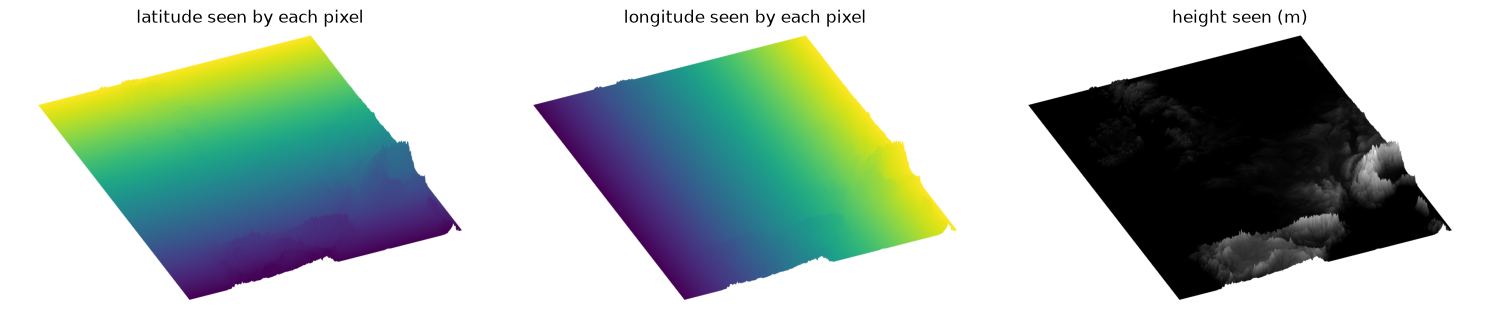

In [3]:
blk = block.Block(z, lat, lon, azimuth=AZIMUTH, tilt=TILT, km_per_px=1.72, zexag=40.0, W=1500, H=900)
fig, axs = plt.subplots(1, 3, figsize=(15, 3.4))
axs[0].imshow(np.where(blk.surf, blk.plat, np.nan)); axs[0].set_title("latitude seen by each pixel")
axs[1].imshow(np.where(blk.surf, blk.plon, np.nan)); axs[1].set_title("longitude seen by each pixel")
axs[2].imshow(np.where(blk.surf, blk.height, np.nan), cmap="gray"); axs[2].set_title("height seen (m)")
for a in axs:
    a.axis("off")
plt.tight_layout(); plt.show()

<div style="background:#E8F5E9;border:3px solid #2E7D32;border-left:14px solid #2E7D32;border-radius:6px;padding:12px 16px;margin:8px 0;color:#1b1b1b">
<div style="color:#2E7D32;font-size:19px;font-weight:bold">RUN</div>
<div style="font-size:16px;font-weight:bold;margin-top:4px">4 · Light and walls</div>
</div>

The relief is lit from the north-west (the convention for relief maps: with light from the south many people
see valleys as ridges). Shading is computed on the terrain grid from its slopes and read through the lookup.
Pixels below the nearest row's surface, down to a fixed thickness, are the **walls** of the slab; a blurred,
shifted copy of the block's silhouette is its shadow on the ground.

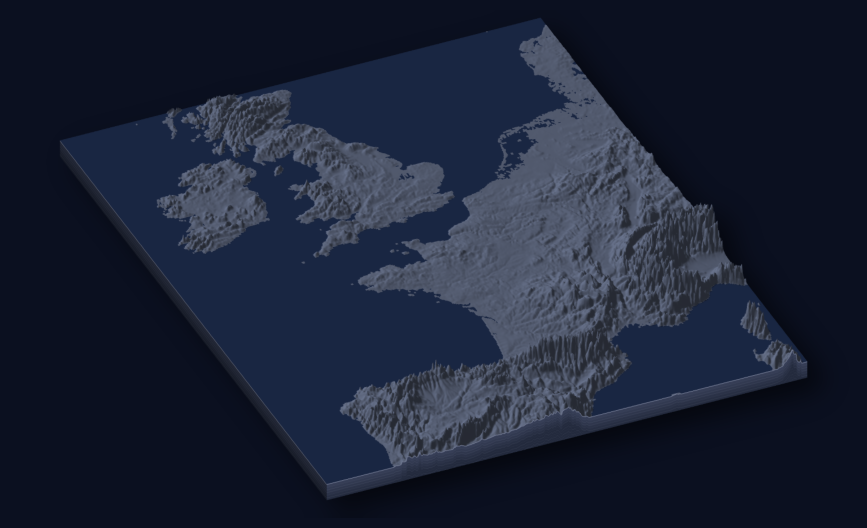

In [4]:
bare = np.where((blk.height > 0)[..., None], C.rgb("#5b647a"), C.rgb("#1d2b4a")).astype(np.float32)
rgba = blk.compose(bare)                         # RGBA, already averaged down from the 2x working size
plt.figure(figsize=(11, 6.6), facecolor=C.BG); plt.imshow(rgba); plt.axis("off"); plt.show()

<div style="background:#E8F5E9;border:3px solid #2E7D32;border-left:14px solid #2E7D32;border-radius:6px;padding:12px 16px;margin:8px 0;color:#1b1b1b">
<div style="color:#2E7D32;font-size:19px;font-weight:bold">RUN</div>
<div style="font-size:16px;font-weight:bold;margin-top:4px">5 · Drape the field</div>
</div>

The wind speed of one hour is sampled at each pixel's (lat, lon), coloured, and laid on the ground with an
opacity that rises from 0 at 8 m/s to full at 12 m/s: calm regions keep the bare relief, and the gale is
the only colour on the picture. The colour bar shows the same ramp and states the cut-off.

In [5]:
speed = np.hypot(wind["u10_cms"], wind["v10_cms"]) / 100.0      # m/s, (hour, lat, lon)
hour = HOUR                                                      # 03 UTC on 2 November with the default setting
s = blk.sample(speed[hour], wind["lat"], wind["lon"])
print("strongest 10-m wind on the block at this hour:", round(float(s[blk.surf].max()), 1), "m/s")

strongest 10-m wind on the block at this hour: 29.4 m/s


<div style="background:#E8F5E9;border:3px solid #2E7D32;border-left:14px solid #2E7D32;border-radius:6px;padding:12px 16px;margin:8px 0;color:#1b1b1b">
<div style="color:#2E7D32;font-size:19px;font-weight:bold">RUN</div>
<div style="font-size:16px;font-weight:bold;margin-top:4px">6 · The finished frame</div>
</div>

`CiaranBlock` adds the linked chart (wind at the ERA5 grid cells nearest Brest and London), the clock, place
names standing on the terrain, a north arrow taken from the geometry, and the credits.


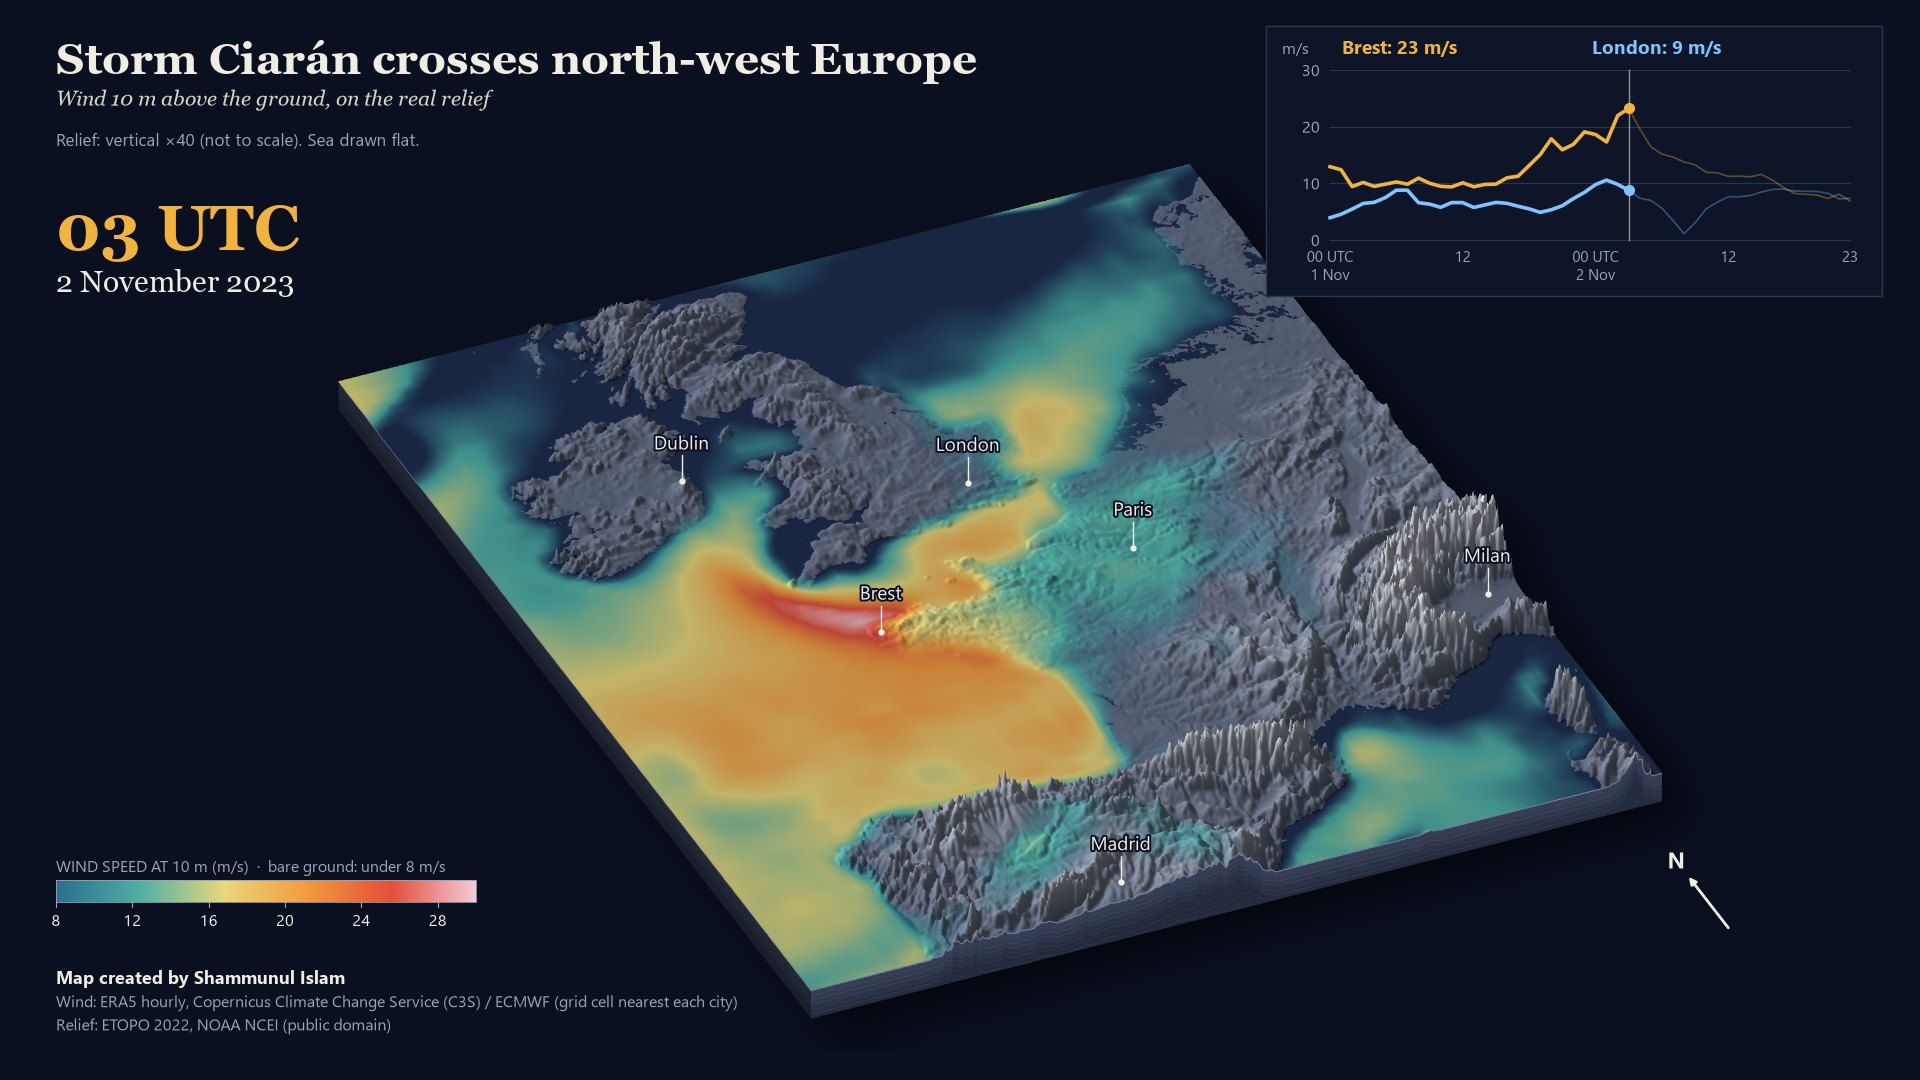

In [6]:
storm = block.CiaranBlock(wind, terrain, azimuth=AZIMUTH, tilt=TILT)
poster = storm.poster(OUT / "block_diagram.png", hour=float(HOUR), scale=POSTER_SCALE)
nb.show(poster)

<div style="background:#E8F5E9;border:3px solid #2E7D32;border-left:14px solid #2E7D32;border-radius:6px;padding:12px 16px;margin:8px 0;color:#1b1b1b">
<div style="color:#2E7D32;font-size:19px;font-weight:bold">RUN — A SHORT PREVIEW IN FAST MODE, THE WHOLE ANIMATION IN FULL MODE</div>
<div style="font-size:16px;font-weight:bold;margin-top:4px">7 · The animation</div>
</div>

47 hours, four frames per hour (the hourly fields are blended linearly in between).

In [7]:
if MODE == "FULL":                               # the whole animation, 1920 x 1080 px
    movie = storm.animate(OUT / "block_diagram.mp4", OUT / "frames_03", per_hour=4)
else:                                            # a short preview: every 8th frame, 960 x 540 px, 12 frames a second
    movie = C.preview(storm.animate, OUT / "block_diagram_preview.mp4", OUT / "frames_03", thin=8, per_hour=4)
nb.video(movie)

<div style="background:#E8F5E9;border:3px solid #2E7D32;border-left:14px solid #2E7D32;border-radius:6px;padding:12px 16px;margin:8px 0;color:#1b1b1b">
<div style="color:#2E7D32;font-size:19px;font-weight:bold">RUN — PASS OR FAIL FOR EVERY OUTPUT</div>
<div style="font-size:16px;font-weight:bold;margin-top:4px">Check the outputs</div>
</div>

The last cell checks that every output exists and is what it should be, and prints PASS or FAIL per check.

In [8]:
size = (int(1920 * POSTER_SCALE), int(1080 * POSTER_SCALE))
checks = [
    ("the poster exists", poster.exists()),
    (f"the poster is {size[0]} x {size[1]} px", nb.image_size(poster) == size),
    ("the lookup covers part of the picture with ground", 0.2 < float(blk.surf.mean()) < 0.95),
    ("a gale is on the block at the chosen hour (over 17 m/s somewhere)", float(s[blk.surf].max()) > 17.0),
]
if not os.environ.get("GIS_PART"):               # (GIS_PART marks a frame worker of the parallel FULL render)
    checks.append(("the movie exists and is not empty", movie is not None and movie.exists() and movie.stat().st_size > 20_000))
nb.verify(checks)

PASS - the poster exists
PASS - the poster is 1920 x 1080 px
PASS - the lookup covers part of the picture with ground
PASS - a gale is on the block at the chosen hour (over 17 m/s somewhere)
PASS - the movie exists and is not empty

All 5 checks passed.


<div style="background:#E3F2FD;border:3px solid #1565C0;border-left:14px solid #1565C0;border-radius:6px;padding:12px 16px;margin:8px 0;color:#1b1b1b">
<div style="color:#1565C0;font-size:19px;font-weight:bold">ON GOOGLE COLAB — ONE ZIP OF THE OUTPUTS</div>
<div style="font-size:16px;font-weight:bold;margin-top:4px">Download (Google Colab)</div>
</div>

On Colab this zips the pictures and movies of the output folder and offers them as one download; anywhere else it
only says where they are.

In [9]:
nb.download(OUT)

33 output file(s) in the folder out/
